### Imports & Config

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np


### Dataset

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = torchvision.datasets.CIFAR10(
    root="../data",
    train=True,
    download=False,   
    transform=transform
)


### Load Trained Model

In [3]:
from model import CifarTinyNet

model = CifarTinyNet()
model.load_state_dict(torch.load("../models/cifar_tinynet.pth"))
model.eval()


CifarTinyNet(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=1152, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=10, bias=True)
)

### Visualize Raw CIFAR Image

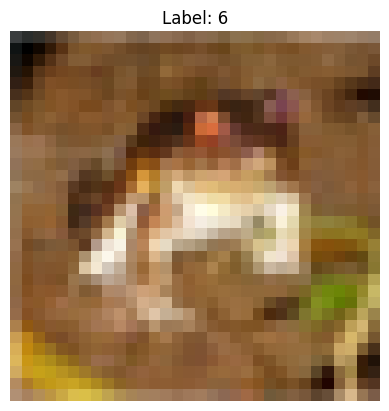

In [4]:
image, label = trainset[0]

# Unnormalize for display
img = image * 0.5 + 0.5

plt.imshow(np.transpose(img.numpy(), (1, 2, 0)))
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()


### Conv1 Feature Maps

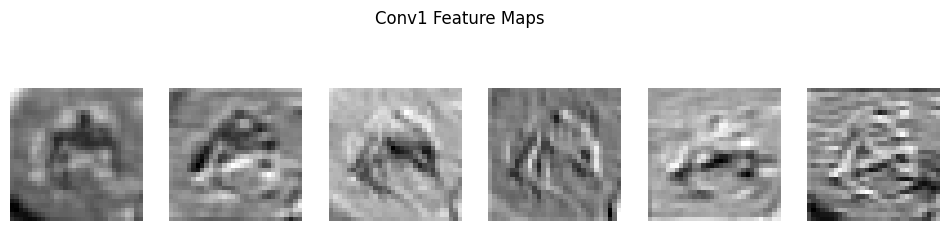

In [5]:
x = image.unsqueeze(0)

with torch.no_grad():
    conv1_out = model.conv1(x)

fig, axs = plt.subplots(1, 6, figsize=(12, 3))
for i in range(6):
    axs[i].imshow(conv1_out[0, i].numpy(), cmap="gray")
    axs[i].axis("off")

plt.suptitle("Conv1 Feature Maps")
plt.show()


### Conv2 Feature Maps

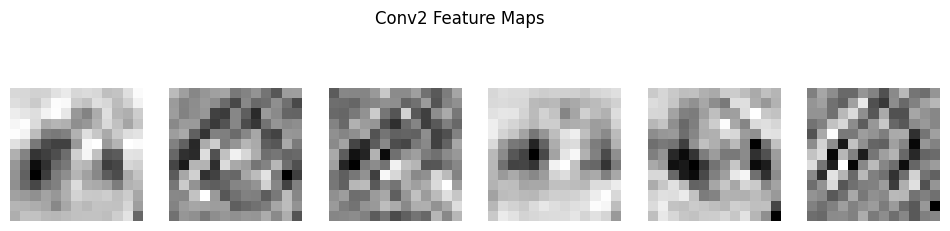

In [6]:
with torch.no_grad():
    x1 = torch.relu(model.conv1(x))
    x1 = torch.max_pool2d(x1, 2)
    conv2_out = model.conv2(x1)

fig, axs = plt.subplots(1, 6, figsize=(12, 3))
for i in range(6):
    axs[i].imshow(conv2_out[0, i].numpy(), cmap="gray")
    axs[i].axis("off")

plt.suptitle("Conv2 Feature Maps")
plt.show()


### Logits & Softmax

In [7]:
with torch.no_grad():
    logits = model(x)
    probs = torch.softmax(logits, dim=1)

print("Logits:")
print(logits.numpy())

print("\nSoftmax Probabilities:")
print(probs.numpy())


Logits:
[[-4.217513  -6.8828864 -0.213682   2.6724224 -1.0479255  1.3421245
   2.4741952  0.8663081 -5.1302824 -6.2900352]]

Softmax Probabilities:
[[4.3680405e-04 3.0389918e-05 2.3940237e-02 4.2908925e-01 1.0394918e-02
  1.1345055e-01 3.5193193e-01 7.0495620e-02 1.7533798e-04 5.4979620e-05]]


### Confidence Bar Plot

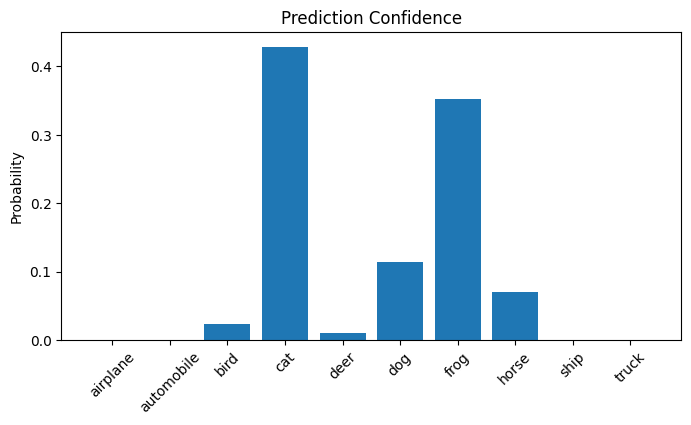

In [8]:
classes = trainset.classes
confidence = probs.squeeze().numpy()

plt.figure(figsize=(8, 4))
plt.bar(classes, confidence)
plt.xticks(rotation=45)
plt.title("Prediction Confidence")
plt.ylabel("Probability")
plt.show()


### Top-K Predictions

In [9]:
topk = torch.topk(probs, k=3)

for i in range(3):
    idx = topk.indices[0][i].item()
    score = topk.values[0][i].item()
    print(f"{i+1}. {classes[idx]} : {score:.3f}")


1. cat : 0.429
2. frog : 0.352
3. dog : 0.113
